# HW2 — Uniform Convergence and the Limits of Learning
**Statistical and Machine Learning** — Université de Haute-Alsace — Saïd El-Jamii

Everything is done with simulations using `numpy` and `matplotlib` only. The random seed is fixed, so the results are reproducible.

**Choice of parameters**
* $\epsilon = 0.05$ and $\delta = 0.05$: these are the usual accuracy and confidence values. With them, the bounds become meaningful only for $m$ in the hundreds, so the interesting region is easy to see.
* $m$ from 10 to 2000: this covers the case where the bounds are useless ($>1$) and the case where deviations become very rare.
* $|H| \in \{5, 10, 50, 100, 500\}$: the size changes by two orders of magnitude. The classes are nested: $H_5$ is the first 5 hypotheses of $H_{500}$, and so on. Only the size changes.
* $N \in \{50, 200, 1000\}$: a small, a medium and a large domain. In Part II, $m$ is chosen as a multiple of $N$ because the ratio $m/N$ is what matters.
* Monte-Carlo repetitions: 10 000 in Q1–Q3, and 500 to 2 000 elsewhere to keep the computation time short. With 2 000 repetitions the standard error of an estimated probability is at most $0.5/\sqrt{2000} \approx 0.011$, which is much smaller than the effects we compare.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)   # fixed seed -> reproducible results

---
# Part I — Simulating Uniform Convergence
Model: the number of errors of $h_j$ on a sample of size $m$ is $E_j \sim \text{Binomial}(m, p_j)$, and $L_S(h_j) = E_j/m$.

## 1. Empirical risk as a random variable

m =   10 | mean of L_S = 0.3001 | std = 0.1452 | sqrt(p(1-p)/m) = 0.1449
m =   50 | mean of L_S = 0.3010 | std = 0.0644 | sqrt(p(1-p)/m) = 0.0648
m =  200 | mean of L_S = 0.3007 | std = 0.0323 | sqrt(p(1-p)/m) = 0.0324
m = 1000 | mean of L_S = 0.2999 | std = 0.0144 | sqrt(p(1-p)/m) = 0.0145


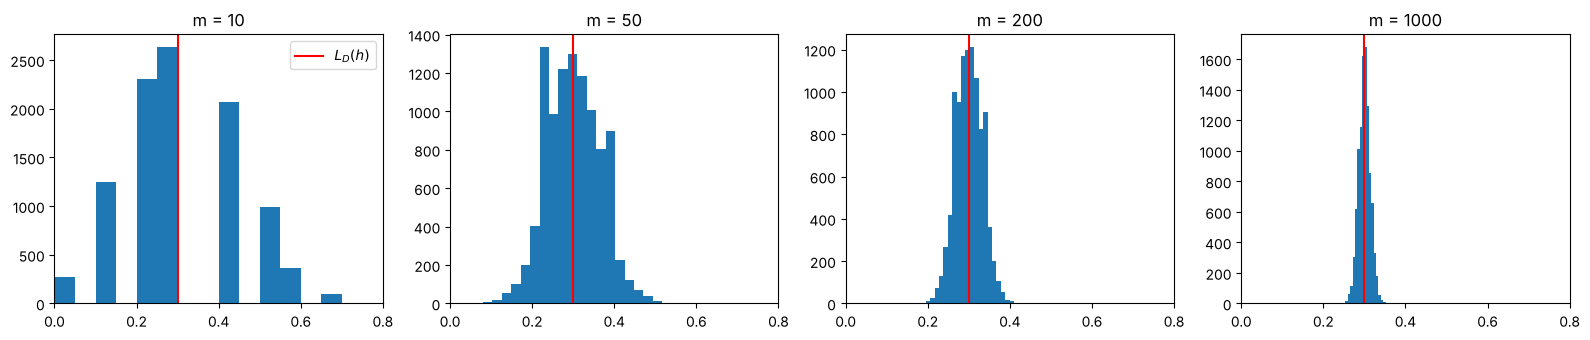

In [2]:
p_true = [0.05, 0.1, 0.2, 0.3, 0.5]   # true risks of 5 hypotheses
p = 0.3                               # we study the hypothesis with L_D(h) = 0.3
m_values = [10, 50, 200, 1000]
R = 10000                             # Monte-Carlo repetitions

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, m in zip(axes, m_values):
    E = rng.binomial(m, p, size=R)    # number of errors on R training samples
    LS = E / m                        # empirical risks
    ax.hist(LS, bins=20)
    ax.axvline(p, color="red", label="$L_D(h)$")
    ax.set_title(f"m = {m}")
    ax.set_xlim(0, 0.8)
    print(f"m = {m:4d} | mean of L_S = {LS.mean():.4f} | std = {LS.std():.4f}"
          f" | sqrt(p(1-p)/m) = {np.sqrt(p * (1 - p) / m):.4f}")
axes[0].legend()
plt.tight_layout()
plt.show()

**Observations.**
* The mean of $L_S(h)$ is always about $0.30 = L_D(h)$. The empirical risk is an unbiased estimator, since $\mathbb E[E/m] = p$.
* The variability decreases when $m$ increases. The simulated standard deviation matches $\sqrt{p(1-p)/m}$: it goes from 0.145 for $m=10$ to 0.014 for $m=1000$. Multiplying $m$ by 100 divides the spread by 10, so the spread decreases like $1/\sqrt m$.
* For small $m$ the histogram is wide and discrete. For large $m$ it is a narrow bell centered on $p$.

## 2. Deviation between empirical and true risk
With $\epsilon = 0.05$, we estimate $\Pr[|L_S(h)-L_D(h)|>\epsilon]$ and compare it with the Hoeffding bound $2e^{-2m\epsilon^2}$.

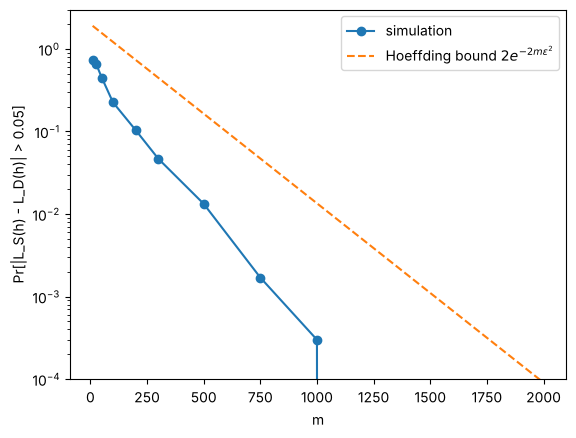

m =   10 | simulation = 0.7370 | Hoeffding = 1.9025
m =   25 | simulation = 0.6632 | Hoeffding = 1.7650
m =   50 | simulation = 0.4502 | Hoeffding = 1.5576
m =  100 | simulation = 0.2247 | Hoeffding = 1.2131
m =  200 | simulation = 0.1037 | Hoeffding = 0.7358
m =  300 | simulation = 0.0467 | Hoeffding = 0.4463
m =  500 | simulation = 0.0133 | Hoeffding = 0.1642
m =  750 | simulation = 0.0017 | Hoeffding = 0.0470
m = 1000 | simulation = 0.0003 | Hoeffding = 0.0135
m = 1500 | simulation = 0.0000 | Hoeffding = 0.0011
m = 2000 | simulation = 0.0000 | Hoeffding = 0.0001


In [3]:
eps = 0.05
m_values = np.array([10, 25, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000])

prob = []
for m in m_values:
    LS = rng.binomial(m, p, size=R) / m
    prob.append(np.mean(np.abs(LS - p) > eps))
prob = np.array(prob)
hoeffding = 2 * np.exp(-2 * m_values * eps**2)

plt.plot(m_values, prob, "o-", label="simulation")
plt.plot(m_values, hoeffding, "--", label="Hoeffding bound $2e^{-2m\\epsilon^2}$")
plt.yscale("log")
plt.ylim(1e-4, 3)
plt.xlabel("m")
plt.ylabel("Pr[|L_S(h) - L_D(h)| > 0.05]")
plt.legend()
plt.show()

for m, a, b in zip(m_values, prob, hoeffding):
    print(f"m = {m:4d} | simulation = {a:.4f} | Hoeffding = {b:.4f}")

**Observations.**
* The simulated probability is always below the bound, so the bound is valid.
* The bound is **conservative, not exact**:
  * it is larger than 1 (useless) for $m \le 100$;
  * at $m=300$ it gives $0.45$, while the real value is $0.047$;
  * at $m=1000$ it gives $0.0135$, while the real value is $0.0003$.
* Both curves decrease exponentially, but the real probability decreases faster.

The reason is that Hoeffding only uses the fact that each error is in $[0,1]$. It is valid for every $p$, so it must cover the worst case ($p = 1/2$, maximal variance), and it cannot be exact for a particular $p$.

## 3. From one hypothesis to uniform convergence
For a class of $|H| = 10$ hypotheses, we compute $\Delta_S = \max_{h\in H}|L_S(h)-L_D(h)|$ for each sample. We compare $\Pr[\Delta_S>\epsilon]$ with the bound $2|H|e^{-2m\epsilon^2}$, which comes from Hoeffding plus the union bound.

true risks: [0.75 0.66 0.33 0.88 0.75 0.5  0.7  0.08 0.36 0.47]


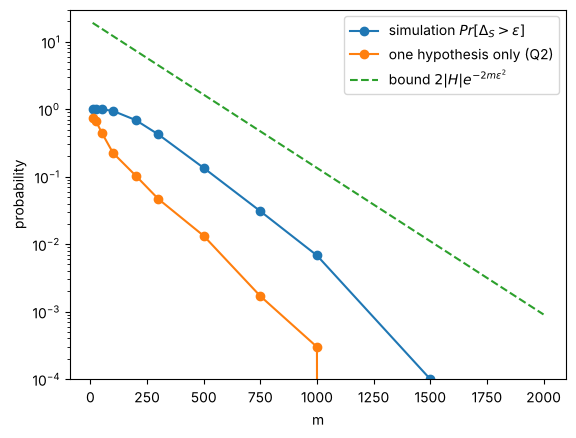

m =   10 | simulation = 1.0000 | bound = 19.0246
m =   25 | simulation = 0.9998 | bound = 17.6499
m =   50 | simulation = 0.9959 | bound = 15.5760
m =  100 | simulation = 0.9428 | bound = 12.1306
m =  200 | simulation = 0.6898 | bound = 7.3576
m =  300 | simulation = 0.4226 | bound = 4.4626
m =  500 | simulation = 0.1349 | bound = 1.6417
m =  750 | simulation = 0.0308 | bound = 0.4704
m = 1000 | simulation = 0.0068 | bound = 0.1348
m = 1500 | simulation = 0.0001 | bound = 0.0111
m = 2000 | simulation = 0.0000 | bound = 0.0009


In [4]:
def prob_uniform(p_H, m, eps, R):
    """Estimate Pr[Delta_S > eps] where Delta_S = max_h |L_S(h) - L_D(h)|."""
    E = rng.binomial(m, p_H, size=(R, len(p_H)))   # one row = one training sample
    LS = E / m
    delta = np.max(np.abs(LS - p_H), axis=1)
    return np.mean(delta > eps)

p_H = rng.uniform(0, 1, size=10)                    # class with |H| = 10
print("true risks:", np.round(p_H, 2))

prob_unif = np.array([prob_uniform(p_H, m, eps, R) for m in m_values])
bound = 2 * len(p_H) * np.exp(-2 * m_values * eps**2)

plt.plot(m_values, prob_unif, "o-", label="simulation $Pr[\\Delta_S > \\epsilon]$")
plt.plot(m_values, prob, "o-", label="one hypothesis only (Q2)")
plt.plot(m_values, bound, "--", label="bound $2|H|e^{-2m\\epsilon^2}$")
plt.yscale("log")
plt.ylim(1e-4, 30)
plt.xlabel("m")
plt.ylabel("probability")
plt.legend()
plt.show()

for m, a, b in zip(m_values, prob_unif, bound):
    print(f"m = {m:4d} | simulation = {a:.4f} | bound = {b:.4f}")

**Observations.**
* $\Pr[\Delta_S>\epsilon]$ is much larger than the probability for one hypothesis. For example, at $m=200$ it is $0.69$ for the class and $0.10$ for one hypothesis. This is because it is enough that **one** hypothesis among the ten deviates.
* It still goes to 0 when $m$ grows: $0.007$ at $m=1000$, and $0$ at $m=2000$. All empirical risks become close to the true risks **at the same time**. This is uniform convergence.
* The bound is valid but very loose. It is larger than 1 up to $m\approx 500$. At $m = 1000$ it gives $0.13$, while the real value is $0.007$, about 20 times smaller. The bound adds the Hoeffding slack of each of the 10 hypotheses.

## 4. Effect of the size of the hypothesis class

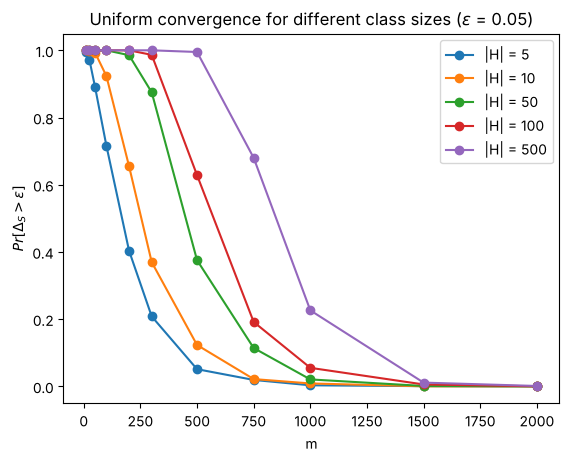

In [5]:
K_list = [5, 10, 50, 100, 500]
p_all = rng.uniform(0, 1, size=500)   # the class of size K = the first K hypotheses
R4 = 2000

for K in K_list:
    probs = [prob_uniform(p_all[:K], m, eps, R4) for m in m_values]
    plt.plot(m_values, probs, "o-", label=f"|H| = {K}")
plt.xlabel("m")
plt.ylabel("$Pr[\\Delta_S > \\epsilon]$")
plt.title("Uniform convergence for different class sizes ($\\epsilon$ = 0.05)")
plt.legend()
plt.show()

**Observations.**
* **A larger $|H|$ makes uniform convergence harder.** The curves move to the right when $|H|$ increases, because more hypotheses means more chances that one of them has a misleading empirical risk.
* **So a larger class needs more data.**
* **But the cost is only logarithmic.** Going from $|H|=5$ to $|H|=500$ (×100) moves the curve by a factor of only about 2–4 in $m$, not 100.
* This matches the bound. Solving $2|H|e^{-2m\epsilon^2} \le \delta$ gives $m \ge \frac{\log|H| + \log(2/\delta)}{2\epsilon^2}$, so $|H|$ only appears through $\log|H|$. The union bound multiplies the failure probability by $|H|$, but each new sample divides it by a constant factor, so a few more samples compensate a much larger class.

## 5. Experimental sample complexity
With $\epsilon = \delta = 0.05$, we look for the smallest tested $m$ (on a grid with step 50) such that $\Pr[\Delta_S>\epsilon] \le \delta$. We compare it with $m \ge \frac{\log(2|H|/\delta)}{2\epsilon^2}$.

In [6]:
delta = 0.05
m_test = np.arange(50, 3001, 50)

print(f"eps = {eps}, delta = {delta}")
for K in K_list:
    m_exp = None
    for m in m_test:
        if prob_uniform(p_all[:K], m, eps, R4) <= delta:
            m_exp = m
            break
    m_th = np.log(2 * K / delta) / (2 * eps**2)
    print(f"|H| = {K:3d} | experimental m = {m_exp:4d} | theoretical m = {m_th:6.0f}")

eps = 0.05, delta = 0.05
|H| =   5 | experimental m =  550 | theoretical m =   1060
|H| =  10 | experimental m =  650 | theoretical m =   1198


|H| =  50 | experimental m =  900 | theoretical m =   1520


|H| = 100 | experimental m = 1050 | theoretical m =   1659


|H| = 500 | experimental m = 1300 | theoretical m =   1981


**Observations.**

| $\lvert H\rvert$ | 5 | 10 | 50 | 100 | 500 |
|---|---|---|---|---|---|
| experimental $m$ | 550 | 650 | 900 | 1050 | 1300 |
| theoretical $m$ | 1060 | 1198 | 1520 | 1659 | 1981 |

* The theoretical value is always larger, by a factor of about 1.5 to 2. Both values grow with $\log|H|$.
* The bound should be read as a **sufficient** guarantee: with this many samples, success is certain. It does not say that fewer samples would fail. It is built from two inequalities that are not tight:
  * Hoeffding assumes the worst variance for each hypothesis;
  * the union bound adds the probabilities as if the bad events never overlapped.
* It must also hold for every possible distribution and class, so for one particular class it is pessimistic.

---
# Part II — Simulating No-Free-Lunch
The domain is $\mathcal X = \{1,\dots,N\}$ with the uniform distribution.

At each repetition:
* a new random target is drawn, with $f(x)\sim \text{Bernoulli}(1/2)$;
* a new sample of size $m$ is drawn;
* the memorization learner is applied: it predicts the observed label on seen inputs and a default value on unseen inputs.

The true risk is computed over the whole domain.

In [7]:
def memorizer_experiment(N, m, rule="zero"):
    """One repetition: random target, random sample, memorization learner.
    Returns (fraction of unseen inputs, true risk)."""
    f = rng.integers(0, 2, size=N)            # random target f(x) ~ Bernoulli(1/2)
    S = rng.integers(0, N, size=m)            # training inputs (uniform on X)
    seen = np.zeros(N, dtype=bool)
    seen[S] = True

    if rule == "zero":
        guess = np.zeros(N, dtype=int)
    elif rule == "one":
        guess = np.ones(N, dtype=int)
    else:                                     # "random"
        guess = rng.integers(0, 2, size=N)

    pred = np.where(seen, f, guess)           # seen -> observed label, unseen -> guess
    unseen_fraction = 1 - seen.mean()
    true_risk = np.mean(pred != f)
    return unseen_fraction, true_risk

## 6. Seen and unseen inputs
A fixed $x$ is missed by one draw with probability $1-1/N$, and the $m$ draws are independent, so $\Pr[x \text{ unseen}] = (1-1/N)^m$.

This is also the expected fraction of unseen points. The fraction is $\frac1N\sum_x \mathbb 1[x\text{ unseen}]$. By linearity of expectation, its mean is $\frac1N\sum_x \Pr[x\text{ unseen}] = (1-1/N)^m$, since all points have the same probability.

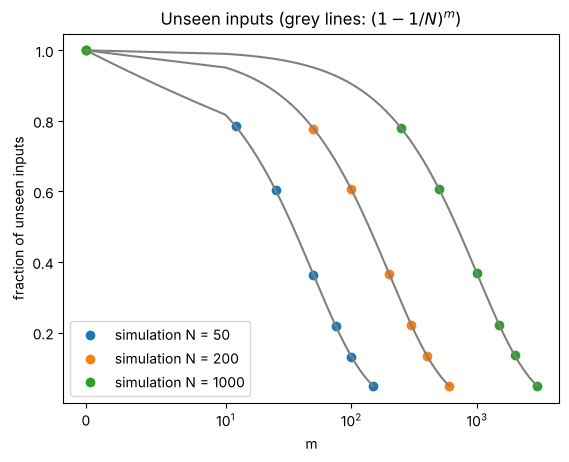

N =   50 | m =   25 | simulation = 0.6035 | (1-1/N)^m = 0.6035
N =   50 | m =   50 | simulation = 0.3631 | (1-1/N)^m = 0.3642
N =   50 | m =  100 | simulation = 0.1316 | (1-1/N)^m = 0.1326
N =  200 | m =  100 | simulation = 0.6062 | (1-1/N)^m = 0.6058
N =  200 | m =  200 | simulation = 0.3668 | (1-1/N)^m = 0.3670
N =  200 | m =  400 | simulation = 0.1348 | (1-1/N)^m = 0.1347
N = 1000 | m =  500 | simulation = 0.6064 | (1-1/N)^m = 0.6064
N = 1000 | m = 1000 | simulation = 0.3675 | (1-1/N)^m = 0.3677
N = 1000 | m = 2000 | simulation = 0.1356 | (1-1/N)^m = 0.1352


In [8]:
N_list = [50, 200, 1000]
ratios = [0, 0.25, 0.5, 1, 1.5, 2, 3]         # m / N
R2 = 1000

results = {}                                  # (N, m) -> (mean unseen fraction, mean risk)
for N in N_list:
    for r in ratios:
        m = int(r * N)
        runs = np.array([memorizer_experiment(N, m) for _ in range(R2)])
        results[(N, m)] = runs.mean(axis=0)

for N in N_list:
    ms = [int(r * N) for r in ratios]
    plt.plot(ms, [results[(N, m)][0] for m in ms], "o", label=f"simulation N = {N}")
    m_line = np.arange(0, 3 * N + 1)
    plt.plot(m_line, (1 - 1 / N) ** m_line, "-", color="grey")
plt.xscale("symlog", linthresh=10)
plt.xlabel("m")
plt.ylabel("fraction of unseen inputs")
plt.title("Unseen inputs (grey lines: $(1-1/N)^m$)")
plt.legend()
plt.show()

for N in N_list:
    for r in [0.5, 1, 2]:
        m = int(r * N)
        print(f"N = {N:4d} | m = {m:4d} | simulation = {results[(N, m)][0]:.4f}"
              f" | (1-1/N)^m = {(1 - 1 / N) ** m:.4f}")

**Observations.** The simulation matches the formula to within $0.001$. With $m = N$ samples, about $37\%\ (\approx e^{-1})$ of the domain is still unseen, because many draws are repetitions. For the three domain sizes, the fraction depends only on $m/N$.

## 7. Error on unseen inputs
On a seen input, the learner gives the true label, so it makes no error. On an unseen input it predicts 0, which is wrong if $f(x)=1$.

The label $f(x)$ of an unseen point is independent of the sample, so $\Pr[f(x)=1] = 1/2$. Therefore
$$\mathbb E[L_D(A(S))] = \frac1N\sum_x \Pr[x\text{ unseen}]\cdot\frac12 = \frac12\Big(1-\frac1N\Big)^m.$$

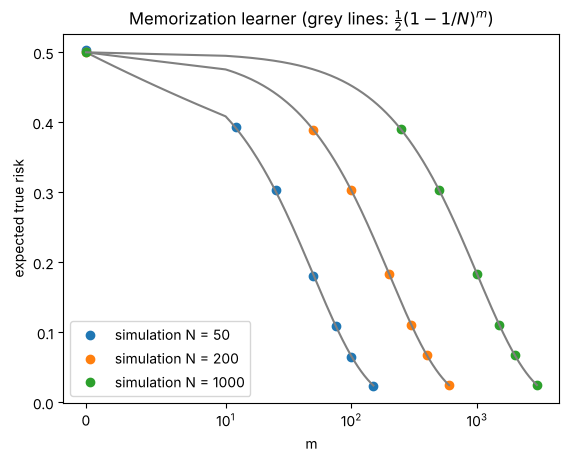

N =   50 | m =   25 | simulation = 0.3028 | theory = 0.3017
N =   50 | m =   50 | simulation = 0.1810 | theory = 0.1821
N =   50 | m =  100 | simulation = 0.0651 | theory = 0.0663
N =  200 | m =  100 | simulation = 0.3035 | theory = 0.3029
N =  200 | m =  200 | simulation = 0.1839 | theory = 0.1835
N =  200 | m =  400 | simulation = 0.0676 | theory = 0.0673
N = 1000 | m =  500 | simulation = 0.3032 | theory = 0.3032
N = 1000 | m = 1000 | simulation = 0.1838 | theory = 0.1838
N = 1000 | m = 2000 | simulation = 0.0678 | theory = 0.0676


In [9]:
for N in N_list:
    ms = [int(r * N) for r in ratios]
    plt.plot(ms, [results[(N, m)][1] for m in ms], "o", label=f"simulation N = {N}")
    m_line = np.arange(0, 3 * N + 1)
    plt.plot(m_line, 0.5 * (1 - 1 / N) ** m_line, "-", color="grey")
plt.xscale("symlog", linthresh=10)
plt.xlabel("m")
plt.ylabel("expected true risk")
plt.title("Memorization learner (grey lines: $\\frac{1}{2}(1-1/N)^m$)")
plt.legend()
plt.show()

for N in N_list:
    for r in [0.5, 1, 2]:
        m = int(r * N)
        print(f"N = {N:4d} | m = {m:4d} | simulation = {results[(N, m)][1]:.4f}"
              f" | theory = {0.5 * (1 - 1 / N) ** m:.4f}")

**Observations.** Simulation and theory agree to within about $0.001$. The learner is perfect on what it has seen and at **chance level (1/2)** on the rest. Its risk only decreases because it sees a larger part of the domain. It needs $m$ of the order of $N$ or more, meaning it has to see almost every point.

## 8. Changing the prediction on unseen inputs

zero   [0.4988 0.3871 0.3032 0.183  0.1124 0.0673 0.0244]


one    [0.4997 0.388  0.3037 0.1844 0.1104 0.0666 0.0243]


random [0.4994 0.3872 0.3029 0.1842 0.1103 0.0677 0.0247]


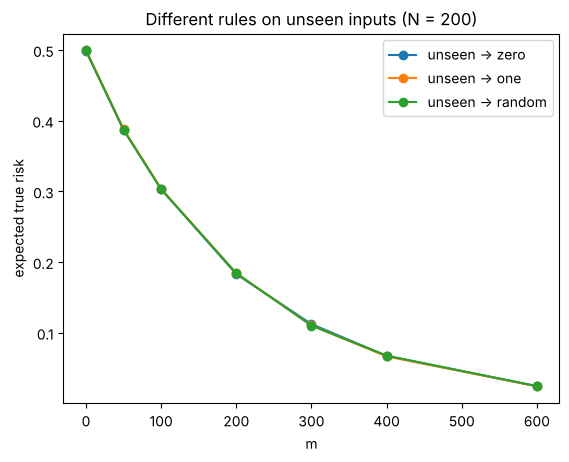

In [10]:
N = 200
m_values_nfl = [0, 50, 100, 200, 300, 400, 600]

for rule in ["zero", "one", "random"]:
    risks = [np.mean([memorizer_experiment(N, m, rule)[1] for _ in range(R2)]) for m in m_values_nfl]
    plt.plot(m_values_nfl, risks, "o-", label=f"unseen -> {rule}")
    print(rule.ljust(6), np.round(risks, 4))
plt.xlabel("m")
plt.ylabel("expected true risk")
plt.title(f"Different rules on unseen inputs (N = {N})")
plt.legend()
plt.show()

**Observations.**
* The three rules give the same expected risk for every $m$, up to Monte-Carlo noise ($\le 0.002$). **No rule consistently outperforms the others.**
* The reason is that the label of an unseen point is a fair coin, independent of everything the learner knows. Whatever the learner predicts, it is wrong with probability 1/2.
* **Link with No-Free-Lunch.** When all target functions are equally likely, the training sample gives no information about the labels outside the sample. Averaged over all tasks, every learner has the same error on unseen points. A rule can only be better on some tasks if it is worse on others. To do better, we have to make an assumption about the target.

---
# Part III — Introducing Prior Knowledge
The target is now a threshold, $f_\theta(x) = \mathbb 1[x>\theta]$, with $\theta$ random in $\{1,\dots,N-1\}$. The learner does ERM over $H = \{h_t(x) = \mathbb 1[x>t]\}$: it computes the training error of every threshold $t$ and keeps the best one.

## 9. Learning with a matching inductive bias

In [11]:
def threshold_experiment(N, m):
    """One repetition: threshold target, ERM over threshold functions.
    Returns the true risk over the whole domain."""
    X = np.arange(1, N + 1)
    theta = rng.integers(1, N)                # theta in {1, ..., N-1}
    f = (X > theta).astype(int)               # target f_theta

    S = rng.integers(1, N + 1, size=m)        # training sample
    y = (S > theta).astype(int)

    # ERM: empirical error of every threshold t, keep the best one
    thresholds = np.arange(1, N)
    errors = [np.sum((S > t).astype(int) != y) for t in thresholds]
    t_hat = thresholds[np.argmin(errors)]

    h = (X > t_hat).astype(int)
    return np.mean(h != f)

N = 200
m_values_thr = [1, 5, 10, 20, 50, 100, 200, 300, 400, 600]
R3 = 500

risk_thr = [np.mean([threshold_experiment(N, m) for _ in range(R3)]) for m in m_values_thr]
risk_rand = [np.mean([memorizer_experiment(N, m)[1] for _ in range(R3)]) for m in m_values_thr]

for m, a, b in zip(m_values_thr, risk_thr, risk_rand):
    print(f"m = {m:3d} | threshold targets + ERM = {a:.4f} | random targets + memorizer = {b:.4f}")

m =   1 | threshold targets + ERM = 0.3364 | random targets + memorizer = 0.4972
m =   5 | threshold targets + ERM = 0.1308 | random targets + memorizer = 0.4867
m =  10 | threshold targets + ERM = 0.0781 | random targets + memorizer = 0.4744
m =  20 | threshold targets + ERM = 0.0436 | random targets + memorizer = 0.4539
m =  50 | threshold targets + ERM = 0.0187 | random targets + memorizer = 0.3896
m = 100 | threshold targets + ERM = 0.0070 | random targets + memorizer = 0.3043
m = 200 | threshold targets + ERM = 0.0030 | random targets + memorizer = 0.1834
m = 300 | threshold targets + ERM = 0.0015 | random targets + memorizer = 0.1116
m = 400 | threshold targets + ERM = 0.0008 | random targets + memorizer = 0.0675
m = 600 | threshold targets + ERM = 0.0002 | random targets + memorizer = 0.0243


**Observations.**
* The risk of the threshold learner decreases very fast, roughly like $1/m$.
* With only $m = 10$ examples, 95 % of the domain is unseen, but the risk is already $0.08$. In Part II, at the same $m$, the risk is $0.47$.
* At $m = 100$: $0.007$ against $0.30$, which is about 40 times smaller.

## 10. Random targets vs. structured targets

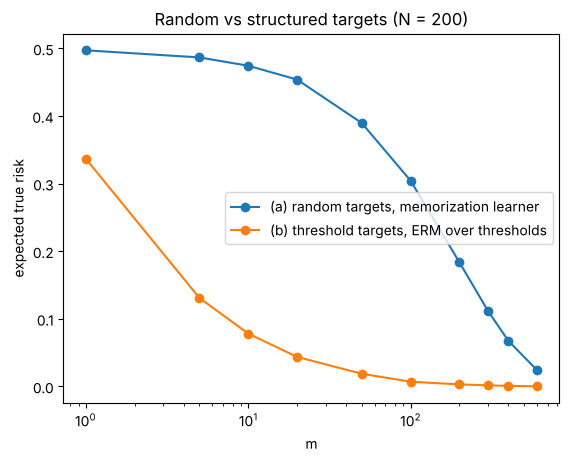

In [12]:
plt.plot(m_values_thr, risk_rand, "o-", label="(a) random targets, memorization learner")
plt.plot(m_values_thr, risk_thr, "o-", label="(b) threshold targets, ERM over thresholds")
plt.xscale("log")
plt.xlabel("m")
plt.ylabel("expected true risk")
plt.title(f"Random vs structured targets (N = {N})")
plt.legend()
plt.show()

**Observations.**
* With **random targets (a)**, the risk stays close to 1/2 as long as $m \ll N$. It only decreases when the domain gets covered.
* With **threshold targets and ERM over thresholds (b)**, the risk falls immediately.

**Why the learner generalizes in (b).** The assumption that the target is a threshold means the whole function depends on a single number $\theta$:
* a negative example at $x$ shows that every point $\le x$ is negative;
* a positive example shows that every point above it is positive.

So a few examples locate $\theta$ in a small interval, and the labels of the unseen points are **deduced** instead of guessed. Only the points between the largest negative example and the smallest positive one stay uncertain, and this interval shrinks when $m$ grows.

In (a) nothing links the labels of different points, so every unseen label is a coin flip. In terms of class size, (a) corresponds to all $2^N$ possible functions, while (b) has only $N-1$ thresholds. The assumption makes the class small, so few samples are enough.

---
## 11. Final analysis

* **Concentration of $L_S(h)$.** $L_S(h)$ is the average of $m$ independent errors. Its spread is $\sqrt{p(1-p)/m}$, so it concentrates around $L_D(h)$ when $m$ increases. Large deviations become exponentially rare, as Hoeffding states.
* **Why uniform convergence needs simultaneous control.** The learner picks its hypothesis using the sample, for example ERM picks the smallest $L_S$. If one hypothesis has an accidentally low $L_S$, it may be the one chosen. We therefore need **all** empirical risks to be close to the true risks at the same time, that is $\Delta_S \le \epsilon$. This is harder than for one hypothesis (Q3).
* **Effect of $|H|$.** More hypotheses means more chances that one of them is misleading, so more data is needed. The cost grows only like $\log|H|$ (Q4–Q5).
* **Why the bounds are conservative.** They combine Hoeffding (worst-case variance) and the union bound (overlaps between bad events are ignored), and they must hold for every distribution. In our experiments, the theoretical $m$ was 1.5 to 2 times the observed one.
* **Random targets make unseen labels unpredictable.** Each unseen label is an independent coin flip, so every prediction is wrong with probability 1/2. The risk $\frac12(1-1/N)^m$ only decreases by seeing more of the domain.
* **No-Free-Lunch.** All rules for unseen inputs have the same expected risk. A learner cannot infer arbitrary unseen labels from the training sample alone.
* **Prior knowledge.** Restricting the targets and the hypothesis class to thresholds reduces the possible functions from $2^N$ to $N-1$, and creates a link between the labels of different points.
* **Why this inductive bias allows generalization.** Each example gives information about a whole part of the domain. Unseen labels can then be deduced, and the risk becomes small while most points have never been seen. Learning is possible because we assume the target belongs to a small class, and this only helps if the assumption is correct.